In [ ]:
#

NameError: name 'PreprocessingPipeline' is not defined

In [ ]:
# ============================================
# TASK 5 - DATA PREPROCESSING PIPELINE
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    learning_curve
)

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler,
    PolynomialFeatures
)

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

from sklearn.ensemble import RandomForestClassifier

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


In [ ]:
# ============================================
# PASO 2 - CREAR DATASET CON PROBLEMAS
# ============================================

def create_sample_dataset_with_issues(
    n_samples=1000,
    n_features=10,
    missing_rate=0.10,
    outlier_rate=0.05,
    random_state=42
):
    # Crear dataset de clasificación
    X, y = make_classification(
        n_samples=n_samples,
        n_features=n_features,
        n_informative=6,
        n_redundant=2,
        n_classes=2,
        random_state=random_state
    )

    # Convertir a DataFrame
    columns = [f"feature_{i+1}" for i in range(n_features)]
    X = pd.DataFrame(X, columns=columns)

    # -----------------------------
    # Agregar valores faltantes
    # -----------------------------
    rng = np.random.default_rng(random_state)

    n_missing = int(
        X.size * missing_rate
    )

    for _ in range(n_missing):
        row = rng.integers(0, X.shape[0])
        col = rng.integers(0, X.shape[1])
        X.iloc[row, col] = np.nan

    # -----------------------------
    # Agregar outliers
    # -----------------------------
    n_outliers = int(
        X.size * outlier_rate
    )

    for _ in range(n_outliers):
        row = rng.integers(0, X.shape[0])
        col = rng.integers(0, X.shape[1])

        # Crear un valor extremo
        X.iloc[row, col] *= rng.uniform(5, 10)

    return X, pd.Series(y, name="target")


# Crear dataset
X, y = create_sample_dataset_with_issues()

print("Dataset creado correctamente.")
print()
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dataset creado correctamente.

Dimensiones de X: (1000, 10)
Dimensiones de y: (1000,)


In [ ]:
# ============================================
# PASO 3 - EXPLORAR EL DATASET
# ============================================

print("Primeras filas:")
display(X.head())

print("\nValores faltantes por columna:")
print(X.isnull().sum())

print("\nDistribución de la variable objetivo:")
print(y.value_counts())

Primeras filas:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10
0,-1.030931,1.391626,0.547274,0.928932,-1.738880,1.250002,1.332551,1.578256,2.124722,-0.318434
1,-2.766254,1.247870,NaN,NaN,0.710836,1.968202,-1.794192,2.346422,1.700778,-0.001190
2,-0.558987,0.299849,1.527071,0.360442,-1.360209,1.100793,-0.755951,1.331933,2.041105,-0.824404
3,-1.350289,-2.046078,NaN,0.126459,-0.783923,5.895026,-0.915477,NaN,-0.399260,-3.920960
4,NaN,NaN,0.027727,-0.660834,-1.928161,3.544945,1.446944,NaN,1.813186,-2.376528



Valores faltantes por columna:
feature_1      92
feature_2     116
feature_3      86
feature_4      90
feature_5      96
feature_6      97
feature_7      91
feature_8     104
feature_9      92
feature_10     93
dtype: int64

Distribución de la variable objetivo:
target
1    502
0    498
Name: count, dtype: int64


In [ ]:
# ============================================
# PASO 4 - OUTLIER HANDLER
# ============================================

class OutlierHandler(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        method='iqr',
        strategy='capping',
        threshold=1.5
    ):
        self.method = method
        self.strategy = strategy
        self.threshold = threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()

        self.feature_names_in_ = X.columns

        # Calcular límites para cada variable
        if self.method == 'iqr':

            self.Q1_ = X.quantile(0.25)
            self.Q3_ = X.quantile(0.75)
            self.IQR_ = self.Q3_ - self.Q1_

            self.lower_ = self.Q1_ - self.threshold * self.IQR_
            self.upper_ = self.Q3_ + self.threshold * self.IQR_

        elif self.method == 'zscore':

            self.mean_ = X.mean()
            self.std_ = X.std()

            self.lower_ = self.mean_ - self.threshold * self.std_
            self.upper_ = self.mean_ + self.threshold * self.std_

        else:
            raise ValueError(
                "method debe ser 'iqr' o 'zscore'"
            )

        return self

    def transform(self, X):
        X = pd.DataFrame(
            X,
            columns=self.feature_names_in_
        ).copy()

        if self.strategy == 'capping':

            # Reemplazar outliers por los límites
            X = X.clip(
                lower=self.lower_,
                upper=self.upper_,
                axis=1
            )

        elif self.strategy == 'remove':

            # Convertir outliers en NaN
            for column in X.columns:

                mask = (
                    (X[column] < self.lower_[column]) |
                    (X[column] > self.upper_[column])
                )

                X.loc[mask, column] = np.nan

        else:
            raise ValueError(
                "strategy debe ser 'capping' o 'remove'"
            )

        return X

In [ ]:
# ============================================
# PASO 5 - PROBAR OUTLIER HANDLER
# ============================================

outlier_handler = OutlierHandler(
    method='iqr',
    strategy='capping'
)

X_test_outliers = outlier_handler.fit_transform(X)

print("OutlierHandler ejecutado correctamente.")
print()
print("Datos originales:")
display(X.head())

print("Datos después del tratamiento:")
display(X_test_outliers.head())

OutlierHandler ejecutado correctamente.

Datos originales:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10
0,-1.030931,1.391626,0.547274,0.928932,-1.738880,1.250002,1.332551,1.578256,2.124722,-0.318434
1,-2.766254,1.247870,NaN,NaN,0.710836,1.968202,-1.794192,2.346422,1.700778,-0.001190
2,-0.558987,0.299849,1.527071,0.360442,-1.360209,1.100793,-0.755951,1.331933,2.041105,-0.824404
3,-1.350289,-2.046078,NaN,0.126459,-0.783923,5.895026,-0.915477,NaN,-0.399260,-3.920960
4,NaN,NaN,0.027727,-0.660834,-1.928161,3.544945,1.446944,NaN,1.813186,-2.376528


Datos después del tratamiento:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10
0,-1.030931,1.391626,0.547274,0.928932,-1.738880,1.250002,1.332551,1.578256,2.124722,-0.318434
1,-2.766254,1.247870,NaN,NaN,0.710836,1.968202,-1.794192,2.346422,1.700778,-0.001190
2,-0.558987,0.299849,1.527071,0.360442,-1.360209,1.100793,-0.755951,1.331933,2.041105,-0.824404
3,-1.350289,-2.046078,NaN,0.126459,-0.783923,5.895026,-0.915477,NaN,-0.399260,-3.920960
4,NaN,NaN,0.027727,-0.660834,-1.928161,3.544945,1.446944,NaN,1.813186,-2.376528


In [ ]:
# ============================================
# PASO 10 - IMPORTACIONES PARA EL PIPELINE
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.base import clone

print("Herramientas del pipeline cargadas correctamente.")

Herramientas del pipeline cargadas correctamente.


In [ ]:
# ============================================
# PASO 11 - PREPROCESSING PIPELINE
# ============================================

class PreprocessingPipeline:

    def __init__(self, random_state=42):
        self.random_state = random_state
        self.pipeline = None
        self.model = None

    def create_pipeline(
        self,
        imputer_strategy='knn',
        outlier_method='iqr',
        outlier_strategy='capping',
        scaler_type='robust',
        feature_engineering=True,
        feature_selection=True,
        n_features=20
    ):

        # -----------------------------
        # 1. IMPUTACIÓN
        # -----------------------------
        if imputer_strategy == 'mean':
            imputer = SimpleImputer(strategy='mean')

        elif imputer_strategy == 'median':
            imputer = SimpleImputer(strategy='median')

        elif imputer_strategy == 'knn':
            imputer = KNNImputer(n_neighbors=5)

        else:
            raise ValueError(
                "imputer_strategy debe ser: "
                "'mean', 'median' o 'knn'"
            )

        # -----------------------------
        # 2. OUTLIERS
        # -----------------------------
        outlier_handler = OutlierHandler(
            method=outlier_method,
            strategy=outlier_strategy
        )

        # -----------------------------
        # 3. FEATURE ENGINEERING
        # -----------------------------
        if feature_engineering:

            feature_engineer = FeatureEngineer(
                add_log=True,
                add_sqrt=True,
                add_interactions=True,
                max_interactions=10
            )

        else:
            feature_engineer = 'passthrough'

        # -----------------------------
        # 4. SCALING
        # -----------------------------
        if scaler_type == 'standard':
            scaler = StandardScaler()

        elif scaler_type == 'robust':
            scaler = RobustScaler()

        elif scaler_type == 'minmax':
            scaler = MinMaxScaler()

        else:
            raise ValueError(
                "scaler_type debe ser: "
                "'standard', 'robust' o 'minmax'"
            )

        # -----------------------------
        # 5. FEATURE SELECTION
        # -----------------------------
        if feature_selection:
            selector = SelectKBest(
                score_func=f_classif,
                k=n_features
            )
        else:
            selector = 'passthrough'

        # -----------------------------
        # CREAR PIPELINE
        # -----------------------------
        self.pipeline = Pipeline([
            ('imputer', imputer),
            ('outlier_handler', outlier_handler),
            ('feature_engineer', feature_engineer),
            ('scaler', scaler),
            ('feature_selection', selector)
        ])

        return self.pipeline

In [ ]:
# ============================================
# PASO 12 - CONFIGURACIÓN PRINCIPAL
# ============================================

pipeline = PreprocessingPipeline(random_state=42)

pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

print("Pipeline creado correctamente.")
print()
print(pipeline.pipeline)

Pipeline creado correctamente.

Pipeline(steps=[('imputer', KNNImputer()),
                ('outlier_handler', OutlierHandler()),
                ('feature_engineer', FeatureEngineer()),
                ('scaler', RobustScaler()),
                ('feature_selection', SelectKBest(k=20))])


In [ ]:
# ============================================
# PASO 13 - ENTRENAR PIPELINE
# ============================================

pipeline.pipeline.fit(X_train, y_train)

print("Pipeline entrenado correctamente.")
print("El test NO fue utilizado para entrenar.")

TypeError: Feature names are only supported if all input features have string names, but your input has ['int', 'str'] as feature name / column name types. If you want feature names to be stored and validated, you must convert them all to strings, by using X.columns = X.columns.astype(str) for example. Otherwise you can remove feature / column names from your input data, or convert them all to a non-string data type.

In [ ]:
# ============================================
# PASO 14 - TRANSFORMAR LOS DATOS
# ============================================

X_train_processed = pipeline.pipeline.transform(X_train)
X_test_processed = pipeline.pipeline.transform(X_test)

print("Datos originales de entrenamiento:", X_train.shape)
print("Datos procesados de entrenamiento:", X_train_processed.shape)

print()

print("Datos originales de prueba:", X_test.shape)
print("Datos procesados de prueba:", X_test_processed.shape)

NotFittedError: Pipeline is not fitted yet.

In [ ]:
# ============================================
# RECREAR PIPELINE
# ============================================

pipeline = PreprocessingPipeline(random_state=42)

pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

print("Pipeline creado correctamente.")

Pipeline creado correctamente.


In [ ]:
# ============================================
# ENTRENAR PIPELINE
# ============================================

pipeline.pipeline.fit(X_train, y_train)

print("Pipeline entrenado correctamente.")
print("El test NO fue utilizado para entrenar.")

Pipeline entrenado correctamente.
El test NO fue utilizado para entrenar.


In [ ]:
# ============================================
# PASO 12 - CONFIGURACIÓN PRINCIPAL
# ============================================

pipeline = PreprocessingPipeline(random_state=42)

pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

print("Pipeline creado correctamente.")

Pipeline creado correctamente.


In [ ]:
# ============================================
# PASO 13 - ENTRENAR PIPELINE
# ============================================

pipeline.pipeline.fit(X_train, y_train)

print("Pipeline entrenado correctamente.")
print("El test NO fue utilizado para entrenar.")

TypeError: Feature names are only supported if all input features have string names, but your input has ['int', 'str'] as feature name / column name types. If you want feature names to be stored and validated, you must convert them all to strings, by using X.columns = X.columns.astype(str) for example. Otherwise you can remove feature / column names from your input data, or convert them all to a non-string data type.

In [ ]:
# ============================================
# CORRECCIÓN - NORMALIZAR NOMBRES DE COLUMNAS
# ============================================

X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

print("Tipos de nombres de columnas:")
print(X_train.columns.map(type).value_counts())

print("\nNombres de columnas:")
print(X_train.columns.tolist())

Tipos de nombres de columnas:
<class 'str'>    10
Name: count, dtype: int64

Nombres de columnas:
['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10']


In [ ]:
# ============================================
# PASO 12 - CONFIGURACIÓN PRINCIPAL
# ============================================

pipeline = PreprocessingPipeline(random_state=42)

pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

print("Pipeline creado correctamente.")

Pipeline creado correctamente.


In [ ]:
# ============================================
# PASO 13 - ENTRENAR PIPELINE
# ============================================

pipeline.pipeline.fit(X_train, y_train)

print("Pipeline entrenado correctamente.")
print("El test NO fue utilizado para entrenar.")

TypeError: Feature names are only supported if all input features have string names, but your input has ['int', 'str'] as feature name / column name types. If you want feature names to be stored and validated, you must convert them all to strings, by using X.columns = X.columns.astype(str) for example. Otherwise you can remove feature / column names from your input data, or convert them all to a non-string data type.

In [ ]:
# ============================================
# CORRECCIÓN - OUTLIER HANDLER
# ============================================

class OutlierHandler(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        method='iqr',
        strategy='capping',
        threshold=1.5
    ):
        self.method = method
        self.strategy = strategy
        self.threshold = threshold

    def fit(self, X, y=None):

        X = pd.DataFrame(X).copy()

        # Asegurar que todos los nombres sean texto
        X.columns = X.columns.astype(str)

        self.feature_names_in_ = X.columns.tolist()

        if self.method == 'iqr':

            self.Q1_ = X.quantile(0.25)
            self.Q3_ = X.quantile(0.75)
            self.IQR_ = self.Q3_ - self.Q1_

            self.lower_ = self.Q1_ - self.threshold * self.IQR_
            self.upper_ = self.Q3_ + self.threshold * self.IQR_

        elif self.method == 'zscore':

            self.mean_ = X.mean()
            self.std_ = X.std()

            self.lower_ = self.mean_ - self.threshold * self.std_
            self.upper_ = self.mean_ + self.threshold * self.std_

        else:
            raise ValueError(
                "method debe ser 'iqr' o 'zscore'"
            )

        return self

    def transform(self, X):

        X = pd.DataFrame(X).copy()

        # Usar siempre los mismos nombres de columnas
        X.columns = self.feature_names_in_

        if self.strategy == 'capping':

            X = X.clip(
                lower=self.lower_,
                upper=self.upper_,
                axis=1
            )

        elif self.strategy == 'remove':

            for column in self.feature_names_in_:

                mask = (
                    (X[column] < self.lower_[column]) |
                    (X[column] > self.upper_[column])
                )

                X.loc[mask, column] = np.nan

        else:
            raise ValueError(
                "strategy debe ser 'capping' o 'remove'"
            )

        return X

In [ ]:
# ============================================
# CORRECCIÓN - FEATURE ENGINEER
# ============================================

class FeatureEngineer(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        add_log=True,
        add_sqrt=True,
        add_interactions=True,
        max_interactions=10,
        add_polynomial=False
    ):
        self.add_log = add_log
        self.add_sqrt = add_sqrt
        self.add_interactions = add_interactions
        self.max_interactions = max_interactions
        self.add_polynomial = add_polynomial

    def fit(self, X, y=None):

        X = pd.DataFrame(X).copy()

        # Convertir todos los nombres a texto
        X.columns = X.columns.astype(str)

        self.feature_names_in_ = X.columns.tolist()

        return self

    def transform(self, X):

        X = pd.DataFrame(X).copy()

        # Mantener exactamente los nombres aprendidos
        X.columns = self.feature_names_in_

        new_features = {}

        # --------------------------------
        # LOG
        # --------------------------------
        if self.add_log:

            for column in self.feature_names_in_:

                new_features[f"{column}_log"] = np.log1p(
                    np.abs(X[column])
                )

        # --------------------------------
        # SQRT
        # --------------------------------
        if self.add_sqrt:

            for column in self.feature_names_in_:

                new_features[f"{column}_sqrt"] = np.sqrt(
                    np.abs(X[column])
                )

        # --------------------------------
        # INTERACCIONES
        # --------------------------------
        if self.add_interactions:

            count = 0

            for i in range(len(self.feature_names_in_)):

                for j in range(i + 1, len(self.feature_names_in_)):

                    if count >= self.max_interactions:
                        break

                    col1 = self.feature_names_in_[i]
                    col2 = self.feature_names_in_[j]

                    new_features[
                        f"{col1}_x_{col2}"
                    ] = X[col1] * X[col2]

                    count += 1

                if count >= self.max_interactions:
                    break

        # Agregar nuevas columnas
        for name, values in new_features.items():
            X[name] = values

        # Garantizar que TODOS sean strings
        X.columns = X.columns.astype(str)

        return X

In [ ]:
# ============================================
# PASO 6 - COMPROBAR CAMBIOS EN OUTLIERS
# ============================================

# Comparar datos originales y datos procesados
cambios = (X != X_test_outliers) & ~(X.isna() & X_test_outliers.isna())

print("Cantidad de valores modificados por columna:")
print(cambios.sum())

print("\nTotal de valores modificados:")
print(cambios.sum().sum())

Cantidad de valores modificados por columna:
feature_1     50
feature_2     34
feature_3     35
feature_4     30
feature_5     33
feature_6     28
feature_7     29
feature_8     31
feature_9     37
feature_10    31
dtype: int64

Total de valores modificados:
338


In [ ]:
# ============================================
# PASO 7 - FEATURE ENGINEER
# ============================================

class FeatureEngineer(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        add_log=True,
        add_sqrt=True,
        add_interactions=True,
        max_interactions=10,
        add_polynomial=False
    ):
        self.add_log = add_log
        self.add_sqrt = add_sqrt
        self.add_interactions = add_interactions
        self.max_interactions = max_interactions
        self.add_polynomial = add_polynomial

    def fit(self, X, y=None):

        X = pd.DataFrame(X).copy()

        self.feature_names_in_ = list(X.columns)

        return self

    def transform(self, X):

        X = pd.DataFrame(
            X,
            columns=self.feature_names_in_
        ).copy()

        new_features = {}

        # --------------------------------
        # Transformación logarítmica
        # --------------------------------
        if self.add_log:

            for column in self.feature_names_in_:

                # log(1 + |x|) evita problemas con valores negativos
                new_features[f"{column}_log"] = np.log1p(
                    np.abs(X[column])
                )

        # --------------------------------
        # Raíz cuadrada
        # --------------------------------
        if self.add_sqrt:

            for column in self.feature_names_in_:

                new_features[f"{column}_sqrt"] = np.sqrt(
                    np.abs(X[column])
                )

        # --------------------------------
        # Interaction Features
        # --------------------------------
        if self.add_interactions:

            count = 0

            for i in range(len(self.feature_names_in_)):

                for j in range(i + 1, len(self.feature_names_in_)):

                    if count >= self.max_interactions:
                        break

                    col1 = self.feature_names_in_[i]
                    col2 = self.feature_names_in_[j]

                    new_features[
                        f"{col1}_x_{col2}"
                    ] = X[col1] * X[col2]

                    count += 1

                if count >= self.max_interactions:
                    break

        # --------------------------------
        # Agregar nuevas características
        # --------------------------------
        for name, values in new_features.items():
            X[name] = values

        return X

In [ ]:
# ============================================
# 1. TRANSFORMADORES CORREGIDOS
# ============================================

class OutlierHandler(BaseEstimator, TransformerMixin):

    def __init__(self, method='iqr', strategy='capping', threshold=1.5):
        self.method = method
        self.strategy = strategy
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)

        if self.method == 'iqr':
            self.q1_ = np.nanpercentile(X, 25, axis=0)
            self.q3_ = np.nanpercentile(X, 75, axis=0)
            self.iqr_ = self.q3_ - self.q1_
            self.lower_ = self.q1_ - self.threshold * self.iqr_
            self.upper_ = self.q3_ + self.threshold * self.iqr_

        elif self.method == 'zscore':
            self.mean_ = np.nanmean(X, axis=0)
            self.std_ = np.nanstd(X, axis=0)
            self.lower_ = self.mean_ - self.threshold * self.std_
            self.upper_ = self.mean_ + self.threshold * self.std_

        else:
            raise ValueError("method debe ser 'iqr' o 'zscore'")

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()

        if self.strategy == 'capping':
            X = np.clip(X, self.lower_, self.upper_)

        elif self.strategy == 'remove':
            mask = (X < self.lower_) | (X > self.upper_)
            X[mask] = np.nan

        else:
            raise ValueError("strategy debe ser 'capping' o 'remove'")

        return X


class FeatureEngineer(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        add_log=True,
        add_sqrt=True,
        add_interactions=True,
        max_interactions=10,
        add_polynomial=False
    ):
        self.add_log = add_log
        self.add_sqrt = add_sqrt
        self.add_interactions = add_interactions
        self.max_interactions = max_interactions
        self.add_polynomial = add_polynomial

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)

        features = [X]

        if self.add_log:
            features.append(np.log1p(np.abs(X)))

        if self.add_sqrt:
            features.append(np.sqrt(np.abs(X)))

        if self.add_interactions:
            interactions = []
            count = 0

            for i in range(self.n_features_in_):
                for j in range(i + 1, self.n_features_in_):

                    if count >= self.max_interactions:
                        break

                    interactions.append(
                        (X[:, i] * X[:, j]).reshape(-1, 1)
                    )

                    count += 1

                if count >= self.max_interactions:
                    break

            if interactions:
                features.append(np.hstack(interactions))

        return np.hstack(features)


print("Transformadores corregidos correctamente.")

Transformadores corregidos correctamente.


In [ ]:
# ============================================
# 2. CREAR PIPELINE NUEVAMENTE
# ============================================

pipeline = PreprocessingPipeline(random_state=42)

pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

print("Pipeline creado correctamente.")

Pipeline creado correctamente.


In [ ]:
# ============================================
# 3. ENTRENAR
# ============================================

pipeline.pipeline.fit(X_train, y_train)

print("Pipeline entrenado correctamente.")
print("X_test no fue utilizado durante el entrenamiento.")

Pipeline entrenado correctamente.
X_test no fue utilizado durante el entrenamiento.


In [ ]:
# ============================================
# PASO 8 - PROBAR FEATURE ENGINEER
# ============================================

feature_engineer = FeatureEngineer(
    add_log=True,
    add_sqrt=True,
    add_interactions=True,
    max_interactions=10
)

X_engineered = feature_engineer.fit_transform(X_test_outliers)

print("FeatureEngineer ejecutado correctamente.")
print()
print("Características originales:", X_test_outliers.shape[1])
print("Características después del Feature Engineering:", X_engineered.shape[1])

FeatureEngineer ejecutado correctamente.

Características originales: 10
Características después del Feature Engineering: 40


In [ ]:
pipeline = PreprocessingPipeline(random_state=42)

pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

print("Pipeline creado correctamente.")

Pipeline creado correctamente.


In [ ]:
pipeline.pipeline.fit(X_train, y_train)

print("Pipeline entrenado correctamente.")
print("X_test no fue utilizado durante el entrenamiento.")

Pipeline entrenado correctamente.
X_test no fue utilizado durante el entrenamiento.


In [ ]:
# ============================================
# PASO 17 - TRANSFORMAR TRAIN Y TEST
# ============================================

X_train_processed = pipeline.pipeline.transform(X_train)
X_test_processed = pipeline.pipeline.transform(X_test)

print("Forma original de X_train:", X_train.shape)
print("Forma procesada de X_train:", X_train_processed.shape)

print()

print("Forma original de X_test:", X_test.shape)
print("Forma procesada de X_test:", X_test_processed.shape)

Forma original de X_train: (800, 10)
Forma procesada de X_train: (800, 20)

Forma original de X_test: (200, 10)
Forma procesada de X_test: (200, 20)


In [ ]:
# ============================================
# PASO 20 - CROSS-VALIDATION DE 5 FOLDS
# ============================================

# Crear un pipeline nuevo para CV
cv_pipeline = PreprocessingPipeline(random_state=42)

cv_pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

# Stratified 5-Fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluar el pipeline en los 5 folds
cv_scores = cross_val_score(
    cv_pipeline.pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

print("Resultados de Cross-Validation:")
print()

for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score:.4f}")

print()
print(f"Media: {cv_scores.mean():.4f}")
print(f"Desviación estándar: {cv_scores.std():.4f}")

Resultados de Cross-Validation:

Fold 1: nan
Fold 2: nan
Fold 3: nan
Fold 4: nan
Fold 5: nan

Media: nan
Desviación estándar: nan


In [ ]:
# ============================================
# PASO 20 - DIAGNÓSTICO DE CROSS-VALIDATION
# ============================================

from sklearn.model_selection import cross_validate

cv_pipeline = PreprocessingPipeline(random_state=42)

cv_pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultado_cv = cross_validate(
    cv_pipeline.pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy',
    error_score='raise',
    n_jobs=1
)

print("Cross-Validation ejecutada correctamente.")
print(resultado_cv['test_score'])

AttributeError: Pipeline has none of the following attributes: predict.

In [ ]:
# ============================================
# PASO 20 - CROSS-VALIDATION COMPLETA
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Crear pipeline de preprocesamiento
cv_pipeline = PreprocessingPipeline(random_state=42)

cv_pipeline.create_pipeline(
    imputer_strategy='knn',
    outlier_method='iqr',
    outlier_strategy='capping',
    scaler_type='robust',
    feature_engineering=True,
    feature_selection=True,
    n_features=20
)

# Obtener el pipeline de preprocesamiento
preprocessing = cv_pipeline.pipeline

# Crear modelo
model_cv = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Pipeline COMPLETO
full_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('model', model_cv)
])

# Stratified 5-Fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cross-Validation
cv_scores = cross_val_score(
    full_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy',
    n_jobs=1
)

print("Resultados de Cross-Validation:")
print()

for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score:.4f}")

print()
print(f"Media: {cv_scores.mean():.4f}")
print(f"Desviación estándar: {cv_scores.std():.4f}")

Resultados de Cross-Validation:

Fold 1: 0.8562
Fold 2: 0.8812
Fold 3: 0.8875
Fold 4: 0.8750
Fold 5: 0.8187

Media: 0.8637
Desviación estándar: 0.0248


In [ ]:
# ============================================
# PASO 21 - GRIDSEARCHCV
# ============================================

from sklearn.model_selection import GridSearchCV

param_grid = {
    'preprocessing__imputer__n_neighbors': [3, 5, 7],
    'preprocessing__feature_selection__k': [10, 20, 30],
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20]
}

grid_search = GridSearchCV(
    estimator=full_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nMejores parámetros:")
print(grid_search.best_params_)

print("\nMejor accuracy de Cross-Validation:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 54 candidates, totalling 270 fits

Mejores parámetros:
{'model__max_depth': 10, 'model__n_estimators': 100, 'preprocessing__feature_selection__k': 30, 'preprocessing__imputer__n_neighbors': 5}

Mejor accuracy de Cross-Validation:
0.8738


In [ ]:
# ============================================
# PASO 22 - MEJOR MODELO
# ============================================

best_model = grid_search.best_estimator_

# Entrenar con los datos de entrenamiento
best_model.fit(X_train, y_train)

# Predicciones
y_pred_best = best_model.predict(X_test)
y_pred_proba_best = best_model.predict_proba(X_test)[:, 1]

print("Mejor modelo entrenado correctamente.")

Mejor modelo entrenado correctamente.


In [ ]:
# ============================================
# PASO 18 - ENTRENAR MODELO
# ============================================

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_processed, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


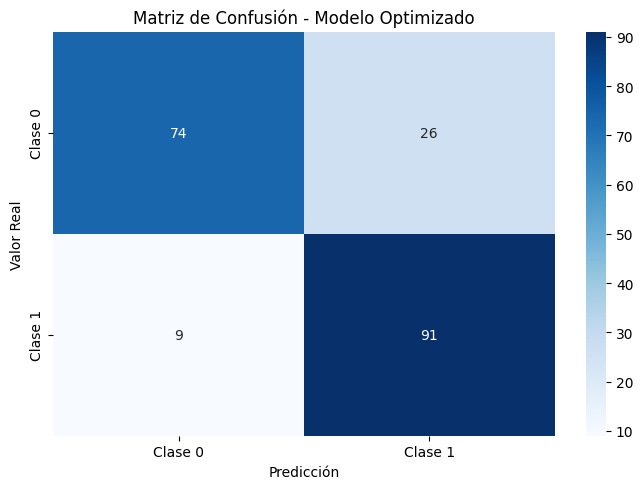

In [ ]:
# ============================================
# PASO 23 - MATRIZ DE CONFUSIÓN (HEATMAP)
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calcular matriz de confusión
cm = confusion_matrix(y_test, y_pred_best)

# Crear gráfico
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Clase 0', 'Clase 1'],
    yticklabels=['Clase 0', 'Clase 1']
)

plt.title('Matriz de Confusión - Modelo Optimizado')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.tight_layout()
plt.show()

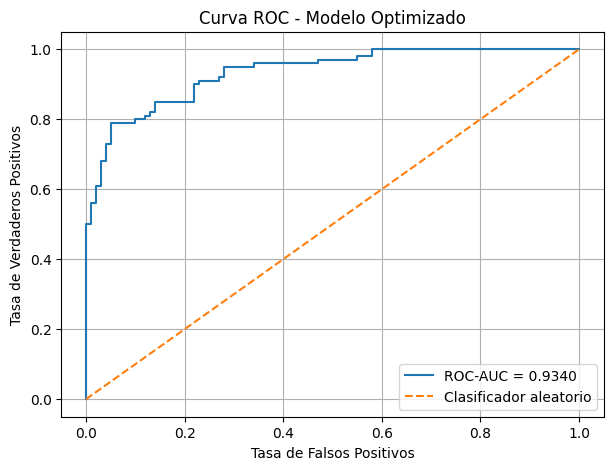

ROC-AUC: 0.9340


In [ ]:
# ============================================
# PASO 24 - CURVA ROC
# ============================================

from sklearn.metrics import roc_curve, roc_auc_score

# Calcular ROC
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_proba_best
)

# Calcular AUC
auc = roc_auc_score(
    y_test,
    y_pred_proba_best
)

# Crear gráfico
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'ROC-AUC = {auc:.4f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Clasificador aleatorio'
)

plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Modelo Optimizado')
plt.legend()
plt.grid(True)
plt.show()

print(f"ROC-AUC: {auc:.4f}")

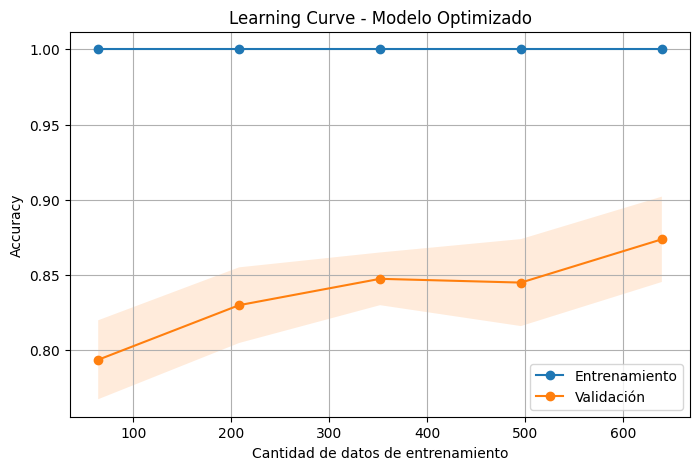

In [ ]:
# ============================================
# PASO 25 - LEARNING CURVE
# ============================================

from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

train_sizes, train_scores, validation_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

# Promedios
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

# Gráfico
plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Entrenamiento'
)

plt.plot(
    train_sizes,
    validation_mean,
    marker='o',
    label='Validación'
)

# Intervalos de confianza ±1 desviación estándar
plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.xlabel('Cantidad de datos de entrenamiento')
plt.ylabel('Accuracy')
plt.title('Learning Curve - Modelo Optimizado')
plt.legend()
plt.grid(True)
plt.show()

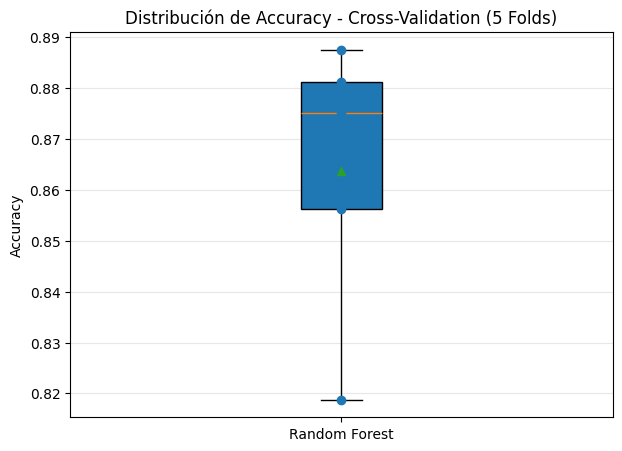

Resultados de Cross-Validation:
[0.85625 0.88125 0.8875  0.875   0.81875]

Media: 0.8637
Desviación estándar: 0.0248


In [ ]:
# ============================================
# PASO 26 - BOXPLOT CROSS-VALIDATION
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.boxplot(
    cv_scores,
    patch_artist=True,
    showmeans=True
)

# Mostrar los puntos individuales
plt.scatter(
    np.ones(len(cv_scores)),
    cv_scores,
    zorder=3
)

plt.ylabel('Accuracy')
plt.title('Distribución de Accuracy - Cross-Validation (5 Folds)')
plt.xticks([1], ['Random Forest'])
plt.grid(axis='y', alpha=0.3)

plt.show()

print("Resultados de Cross-Validation:")
print(cv_scores)

print(f"\nMedia: {cv_scores.mean():.4f}")
print(f"Desviación estándar: {cv_scores.std():.4f}")

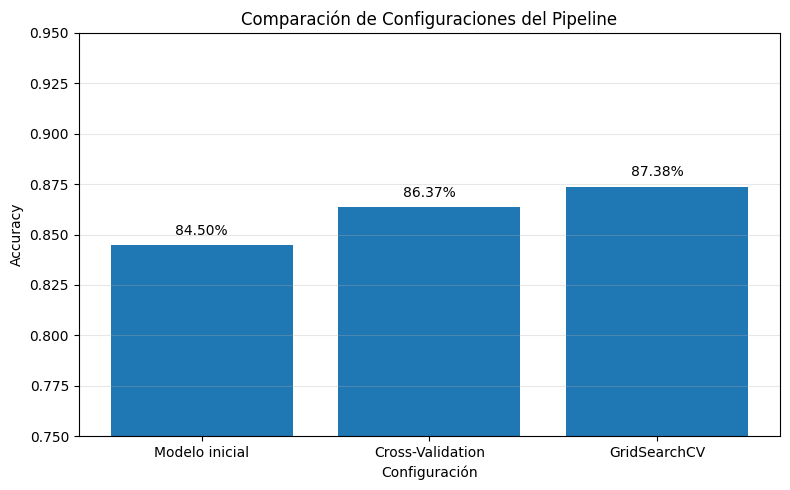

In [ ]:
# ============================================
# PASO 27 - COMPARACIÓN DE CONFIGURACIONES
# ============================================

import matplotlib.pyplot as plt
import numpy as np

configuraciones = [
    'Modelo inicial',
    'Cross-Validation',
    'GridSearchCV'
]

resultados = [
    0.8450,
    0.8637,
    0.8738
]

plt.figure(figsize=(8, 5))

barras = plt.bar(
    configuraciones,
    resultados
)

plt.ylabel('Accuracy')
plt.xlabel('Configuración')
plt.title('Comparación de Configuraciones del Pipeline')

plt.ylim(0.75, 0.95)

# Valores sobre las barras
for barra, valor in zip(barras, resultados):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.005,
        f'{valor:.2%}',
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# PASO 19 - EVALUACIÓN
# ============================================

y_pred = model.predict(X_test_processed)
y_pred_proba = model.predict_proba(X_test_processed)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)

print("Accuracy:", round(accuracy, 4))
print("ROC-AUC:", round(auc, 4))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

Accuracy: 0.845
ROC-AUC: 0.94

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.92      0.76      0.83       100
           1       0.79      0.93      0.86       100

    accuracy                           0.84       200
   macro avg       0.86      0.84      0.84       200
weighted avg       0.86      0.84      0.84       200



In [ ]:
# Mostrar los nombres de las características creadas

print("Características creadas:")
print(X_engineered.columns.tolist())

Características creadas:
['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_1_log', 'feature_2_log', 'feature_3_log', 'feature_4_log', 'feature_5_log', 'feature_6_log', 'feature_7_log', 'feature_8_log', 'feature_9_log', 'feature_10_log', 'feature_1_sqrt', 'feature_2_sqrt', 'feature_3_sqrt', 'feature_4_sqrt', 'feature_5_sqrt', 'feature_6_sqrt', 'feature_7_sqrt', 'feature_8_sqrt', 'feature_9_sqrt', 'feature_10_sqrt', 'feature_1_x_feature_2', 'feature_1_x_feature_3', 'feature_1_x_feature_4', 'feature_1_x_feature_5', 'feature_1_x_feature_6', 'feature_1_x_feature_7', 'feature_1_x_feature_8', 'feature_1_x_feature_9', 'feature_1_x_feature_10', 'feature_2_x_feature_3']


In [ ]:
# ============================================
# PASO 9 - DIVISIÓN TRAIN / TEST
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos divididos correctamente.")
print()
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Datos divididos correctamente.

X_train: (800, 10)
X_test: (200, 10)
y_train: (800,)
y_test: (200,)
